In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"C:\Users\nidap\Desktop\main project\PYTHON\python mini\sales with pandas and numpy\Sales_Analysis.csv")

df.head(10)

,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Payment_Method,Customer_Notes
0,ORD-1001,2025-01-16,A4 Paper Ream,Office Supplies,South,20.0,6.99,139.80,37.48,Cash,NaN
1,ORD-1002,2025-01-24,USB-C Hub,Technology,North,5.0,34.50,172.50,NaN,Cash,NaN
2,ORD-1003,2025-01-25,Notebook Pack (5),Office Supplies,West,17.0,12.99,220.83,NaN,Credit Card,NaN
3,ORD-1004,2025-01-28,Mechanical Keyboard,NaN,West,5.0,79.99,399.95,55.77,Debit Card,NaN
4,ORD-1005,2025-02-01,Laptop 15.6in,Technology,West,1.0,849.00,849.00,94.27,Credit Card,NaN
5,ORD-1006,2025-02-02,Laptop 15.6in,Technology,West,5.0,849.00,4245.00,730.55,PayPal,NaN
6,ORD-1007,2025-02-03,Laptop 15.6in,Technology,South,1.0,849.00,849.00,80.96,Credit Card,NaN
7,ORD-1008,2025-02-04,27-inch Monitor,Technology,East,2.0,229.00,NaN,37.61,PayPal,NaN
8,ORD-1009,2025-02-05,Mechanical Keyboard,Technology,North,1.0,79.99,79.99,6.83,PayPal,NaN
9,ORD-1010,2025-02-16,Filing Cabinet,Furniture,North,1.0,139.00,139.00,25.25,PayPal,NaN


In [2]:
print("column names",df.columns)

column names Index(['Order_ID', 'Order_Date', 'Product', 'Category', 'Region', 'Quantity',
       'Unit_Price', 'Sales', 'Profit', 'Payment_Method', 'Customer_Notes'],
      dtype='object')


In [4]:
df.duplicated().sum()

np.int64(2)

In [5]:
df=df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

Order_ID           0
Order_Date         0
Product            0
Category           6
Region             7
Quantity           8
Unit_Price         0
Sales              7
Profit             8
Payment_Method     6
Customer_Notes    90
dtype: int64

In [7]:
df = df.drop(columns=["Customer_Notes"])
df.isnull().sum()

Order_ID          0
Order_Date        0
Product           0
Category          6
Region            7
Quantity          8
Unit_Price        0
Sales             7
Profit            8
Payment_Method    6
dtype: int64

In [24]:
df[["Product", "Sales"]]

,Product,Sales
0,A4 Paper Ream,139.80
1,USB-C Hub,172.50
2,Notebook Pack (5),220.83
3,Mechanical Keyboard,399.95
4,Laptop 15.6in,849.00
...,...,...
95,Filing Cabinet,278.00
96,Ballpoint Pens (Box of 50),101.88
97,HD Webcam,199.96
98,LED Desk Lamp,29.99


In [8]:
df.shape

(100, 10)

In [9]:
num_cols = df.select_dtypes(include=np.number).columns

df[num_cols] = df[num_cols].fillna(df[num_cols].mean())

In [10]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Product           0
Category          6
Region            7
Quantity          0
Unit_Price        0
Sales             0
Profit            0
Payment_Method    6
dtype: int64

In [14]:
df["Category"] = df["Category"].fillna(df["Category"].mode()[0])

df["Region"] = df["Region"].fillna(df["Region"].mode()[0])

df["Payment_Method"] = df["Payment_Method"].fillna(df["Payment_Method"].mode()[0])
df.isnull().sum()

Order_ID          0
Order_Date        0
Product           0
Category          0
Region            0
Quantity          0
Unit_Price        0
Sales             0
Profit            0
Payment_Method    0
dtype: int64

In [16]:
df.loc[df["Category"] == "Technology", ["Product", "Category", "Sales"]]

,Product,Category,Sales
1,USB-C Hub,Technology,172.500000
3,Mechanical Keyboard,Technology,399.950000
4,Laptop 15.6in,Technology,849.000000
5,Laptop 15.6in,Technology,4245.000000
6,Laptop 15.6in,Technology,849.000000
7,27-inch Monitor,Technology,428.482043
8,Mechanical Keyboard,Technology,79.990000
12,Wireless Mouse,Technology,428.482043
13,USB-C Hub,Technology,34.500000
17,27-inch Monitor,Technology,229.000000


In [18]:
df.iloc[0:5]

,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Payment_Method
0,ORD-1001,2025-01-16,A4 Paper Ream,Office Supplies,South,20.0,6.99,139.80,37.480000,Cash
1,ORD-1002,2025-01-24,USB-C Hub,Technology,North,5.0,34.50,172.50,61.342935,Cash
2,ORD-1003,2025-01-25,Notebook Pack (5),Office Supplies,West,17.0,12.99,220.83,61.342935,Credit Card
3,ORD-1004,2025-01-28,Mechanical Keyboard,Technology,West,5.0,79.99,399.95,55.770000,Debit Card
4,ORD-1005,2025-02-01,Laptop 15.6in,Technology,West,1.0,849.00,849.00,94.270000,Credit Card


In [19]:
np.mean(df["Sales"])

np.float64(428.4820430107527)

In [20]:
np.square(df["Sales"])

0      19544.0400
1      29756.2500
2      48765.8889
3     159960.0025
4     720801.0000
         ...     
95     77284.0000
96     10379.5344
97     39984.0016
98       899.4001
99    108880.2009
Name: Sales, Length: 100, dtype: float64

In [21]:
def add_discount(data):
    data["Discounted_Sales"] = data["Sales"] * 0.90
    return data

In [23]:
df = df.pipe(add_discount)
df[["Sales", "Discounted_Sales"]].head()

,Sales,Discounted_Sales
0,139.80,125.820
1,172.50,155.250
2,220.83,198.747
3,399.95,359.955
4,849.00,764.100


In [25]:
np.union1d(df["Sales"], df["Profit"])

array([3.36000000e+00, 4.73000000e+00, 5.25000000e+00, 5.97000000e+00,
       6.09000000e+00, 6.42000000e+00, 6.48000000e+00, 6.83000000e+00,
       6.85000000e+00, 6.89000000e+00, 7.54000000e+00, 7.77000000e+00,
       7.83000000e+00, 7.90000000e+00, 8.06000000e+00, 8.36000000e+00,
       9.57000000e+00, 9.78000000e+00, 9.95000000e+00, 1.02600000e+01,
       1.12500000e+01, 1.16600000e+01, 1.21100000e+01, 1.21800000e+01,
       1.26400000e+01, 1.38900000e+01, 1.53000000e+01, 1.53500000e+01,
       1.55800000e+01, 1.63200000e+01, 1.73800000e+01, 1.74900000e+01,
       1.76300000e+01, 1.83000000e+01, 2.16700000e+01, 2.22800000e+01,
       2.32300000e+01, 2.37100000e+01, 2.52500000e+01, 2.56100000e+01,
       2.59800000e+01, 2.61900000e+01, 2.72400000e+01, 2.79600000e+01,
       2.82100000e+01, 2.85800000e+01, 2.87900000e+01, 2.89000000e+01,
       2.99900000e+01, 3.02200000e+01, 3.03500000e+01, 3.17400000e+01,
       3.39600000e+01, 3.45000000e+01, 3.49500000e+01, 3.56700000e+01,
      

In [26]:
np.intersect1d(df["Sales"], df["Profit"])

array([], dtype=float64)

In [27]:
np.setdiff1d(df["Sales"], df["Profit"])

array([  25.98      ,   27.96      ,   29.99      ,   33.96      ,
         34.5       ,   34.95      ,   39.96      ,   46.        ,
         49.99      ,   51.96      ,   57.5       ,   59.94      ,
         59.98      ,   59.99      ,   69.        ,   69.9       ,
         79.92      ,   79.99      ,   84.        ,   89.97      ,
         93.39      ,   97.86      ,   99.98      ,  101.88      ,
        103.5       ,  115.        ,  118.83      ,  119.96      ,
        119.99      ,  132.81      ,  139.        ,  139.8       ,
        139.86      ,  149.85      ,  149.97      ,  159.98      ,
        172.5       ,  179.82      ,  181.86      ,  184.        ,
        199.96      ,  207.84      ,  220.83      ,  229.        ,
        230.        ,  259.8       ,  278.        ,  329.97      ,
        378.        ,  399.95      ,  428.48204301,  439.96      ,
        458.        ,  479.96      ,  556.        ,  687.        ,
        756.        ,  849.        ,  916.        , 1047.     

In [28]:
df.sort_values(by="Sales", ascending=True)

,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Payment_Method,Discounted_Sales
32,ORD-1033,2025-05-22,Notebook Pack (5),Office Supplies,West,2.0,12.99,25.98,7.900000,Debit Card,23.382
56,ORD-1057,2025-08-19,A4 Paper Ream,Office Supplies,South,4.0,6.99,27.96,8.060000,Credit Card,25.164
64,ORD-1065,2025-09-08,A4 Paper Ream,Office Supplies,South,4.0,6.99,27.96,5.970000,PayPal,25.164
21,ORD-1022,2025-03-29,LED Desk Lamp,Furniture,South,1.0,29.99,29.99,6.090000,Debit Card,26.991
98,ORD-1099,2025-12-21,LED Desk Lamp,Technology,South,1.0,29.99,29.99,5.250000,Debit Card,26.991
...,...,...,...,...,...,...,...,...,...,...,...
22,ORD-1023,2025-04-12,Standing Desk,Furniture,Central,4.0,349.00,1396.00,61.342935,Credit Card,1256.400
82,ORD-1083,2025-10-28,Laptop 15.6in,Technology,East,2.0,849.00,1698.00,213.700000,Bank Transfer,1528.200
87,ORD-1088,2025-11-04,Laptop 15.6in,Technology,East,4.0,849.00,3396.00,444.320000,PayPal,3056.400
5,ORD-1006,2025-02-02,Laptop 15.6in,Technology,West,5.0,849.00,4245.00,730.550000,PayPal,3820.500


In [29]:
df.sort_values(by="Sales", ascending=False)

,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Payment_Method,Discounted_Sales
81,ORD-1082,2025-10-21,Laptop 15.6in,Technology,Central,5.0,849.00,4245.00,378.54,Debit Card,3820.500
5,ORD-1006,2025-02-02,Laptop 15.6in,Technology,West,5.0,849.00,4245.00,730.55,PayPal,3820.500
87,ORD-1088,2025-11-04,Laptop 15.6in,Technology,East,4.0,849.00,3396.00,444.32,PayPal,3056.400
82,ORD-1083,2025-10-28,Laptop 15.6in,Technology,East,2.0,849.00,1698.00,213.70,Bank Transfer,1528.200
59,ORD-1060,2025-08-27,Standing Desk,Technology,Central,4.0,349.00,1396.00,213.70,Debit Card,1256.400
...,...,...,...,...,...,...,...,...,...,...,...
98,ORD-1099,2025-12-21,LED Desk Lamp,Technology,South,1.0,29.99,29.99,5.25,Debit Card,26.991
21,ORD-1022,2025-03-29,LED Desk Lamp,Furniture,South,1.0,29.99,29.99,6.09,Debit Card,26.991
56,ORD-1057,2025-08-19,A4 Paper Ream,Office Supplies,South,4.0,6.99,27.96,8.06,Credit Card,25.164
64,ORD-1065,2025-09-08,A4 Paper Ream,Office Supplies,South,4.0,6.99,27.96,5.97,PayPal,25.164


In [32]:
print("Maximum Sales:", np.max(df["Sales"]))
print("Minimum Sales:", np.min(df["Sales"]))
print("Standard Deviation:", np.std(df["Sales"]))

Maximum Sales: 4245.0
Minimum Sales: 25.98
Standard Deviation: 712.2273027349612


In [34]:
df[df["Quantity"] > 5]

,Order_ID,Order_Date,Product,Category,Region,Quantity,Unit_Price,Sales,Profit,Payment_Method,Discounted_Sales
0,ORD-1001,2025-01-16,A4 Paper Ream,Office Supplies,South,20.000000,6.99,139.800000,37.480000,Cash,125.820000
2,ORD-1003,2025-01-25,Notebook Pack (5),Office Supplies,West,17.000000,12.99,220.830000,61.342935,Credit Card,198.747000
11,ORD-1012,2025-02-21,Whiteboard Markers (Set),Office Supplies,East,8.000000,9.99,79.920000,26.190000,Cash,71.928000
15,ORD-1016,2025-03-08,LED Desk Lamp,Furniture,East,5.663043,29.99,29.990000,3.360000,Debit Card,26.991000
17,ORD-1018,2025-03-13,27-inch Monitor,Technology,South,5.663043,229.00,229.000000,37.640000,Cash,206.100000
18,ORD-1019,2025-03-15,Whiteboard Markers (Set),Office Supplies,North,6.000000,9.99,59.940000,61.342935,Credit Card,53.946000
19,ORD-1020,2025-03-24,Notebook Pack (5),Office Supplies,South,20.000000,12.99,259.800000,77.000000,Bank Transfer,233.820000
20,ORD-1021,2025-03-24,Notebook Pack (5),Office Supplies,South,16.000000,12.99,207.840000,58.280000,Credit Card,187.056000
28,ORD-1029,2025-05-13,Whiteboard Markers (Set),Office Supplies,East,18.000000,9.99,179.820000,44.820000,Cash,161.838000
31,ORD-1032,2025-05-16,A4 Paper Ream,Office Supplies,South,17.000000,6.99,118.830000,28.900000,Cash,106.947000


In [36]:
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100
df[["Sales", "Profit", "Profit_Margin"]].head()

,Sales,Profit,Profit_Margin
0,139.80,37.480000,26.809728
1,172.50,61.342935,35.561122
2,220.83,61.342935,27.778352
3,399.95,55.770000,13.944243
4,849.00,94.270000,11.103651


In [37]:
df["Category"].unique()

array(['Office Supplies', 'Technology', 'Furniture'], dtype=object)

In [38]:
df["Category"].nunique()

3

In [39]:
df["Category"].value_counts()

Category
Technology         45
Office Supplies    34
Furniture          21
Name: count, dtype: int64

In [40]:
df.shape

(100, 12)

In [41]:
df.isnull().sum()

Order_ID            0
Order_Date          0
Product             0
Category            0
Region              0
Quantity            0
Unit_Price          0
Sales               0
Profit              0
Payment_Method      0
Discounted_Sales    0
Profit_Margin       0
dtype: int64

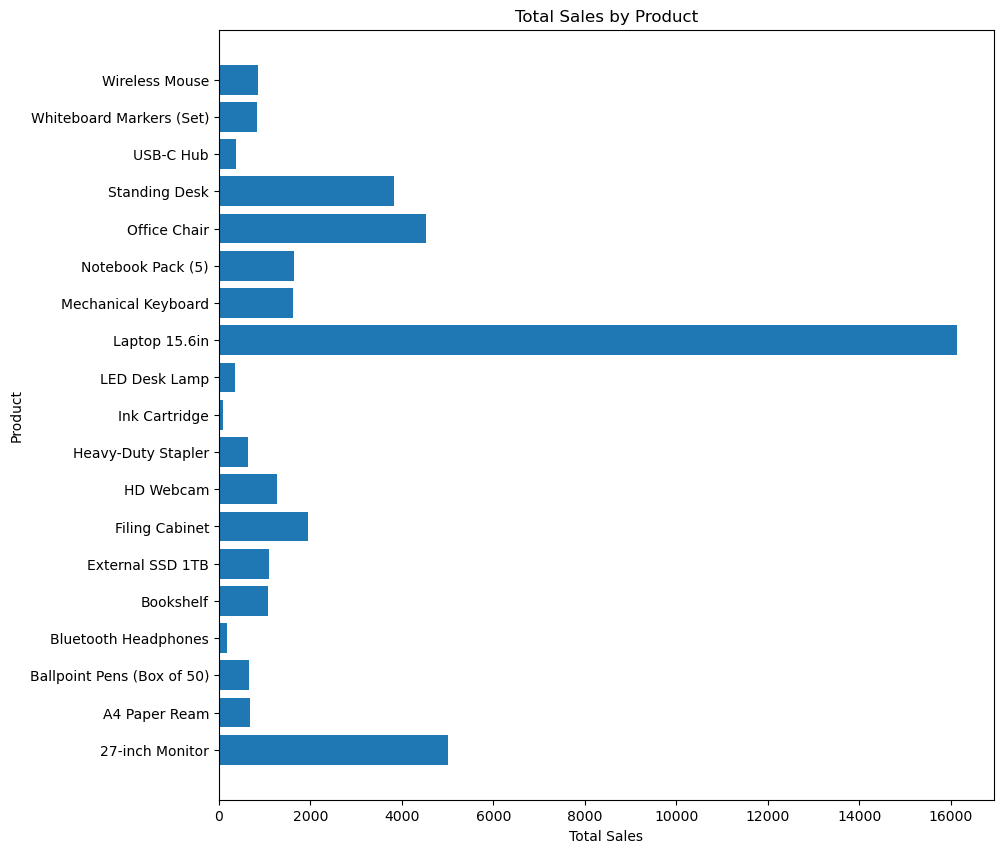

In [55]:
product_sales = df.groupby("Product")["Sales"].sum()
plt.figure(figsize=(10,10))
plt.barh(product_sales.index, product_sales.values)
plt.title("Total Sales by Product")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.show()

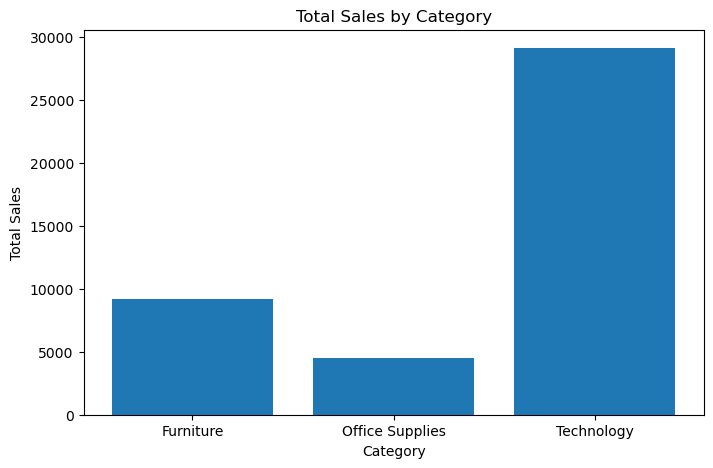

In [48]:
category_sales = df.groupby("Category")["Sales"].sum()
plt.figure(figsize=(8, 5))
plt.bar(category_sales.index, category_sales.values)
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.show()

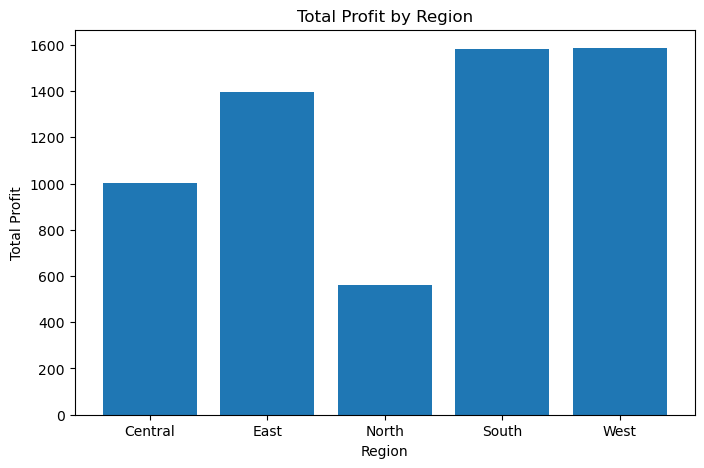

In [49]:
region_profit = df.groupby("Region")["Profit"].sum()
plt.figure(figsize=(8, 5))
plt.bar(region_profit.index, region_profit.values)
plt.title("Total Profit by Region")
plt.xlabel("Region")
plt.ylabel("Total Profit")
plt.show()

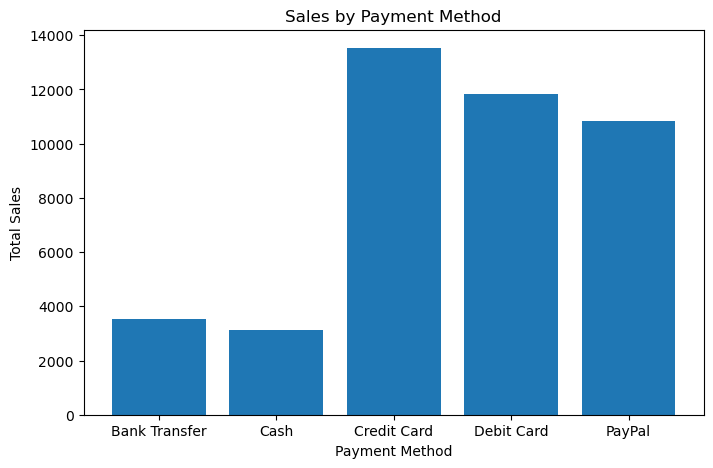

In [50]:
payment_sales = df.groupby("Payment_Method")["Sales"].sum()
plt.figure(figsize=(8, 5))
plt.bar(payment_sales.index, payment_sales.values)
plt.title("Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.show()

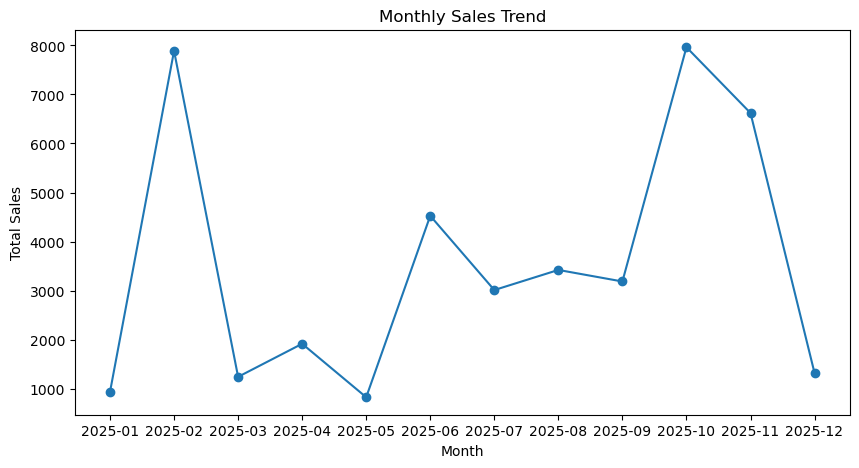

In [51]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])
monthly_sales = df.groupby(df["Order_Date"].dt.to_period("M"))["Sales"].sum()
plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.show()

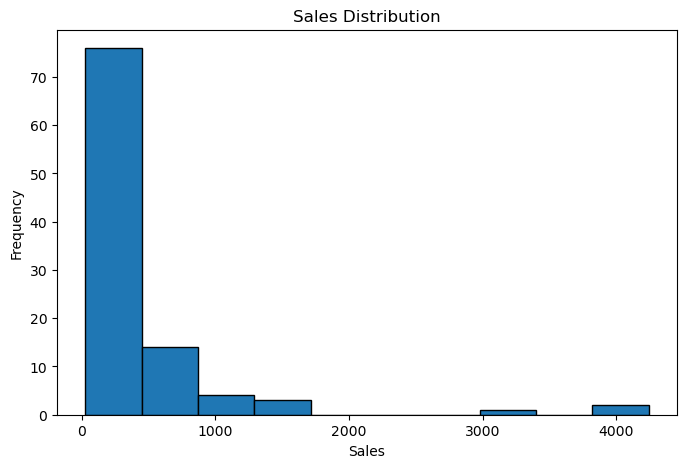

In [52]:
plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=10, edgecolor="black")
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

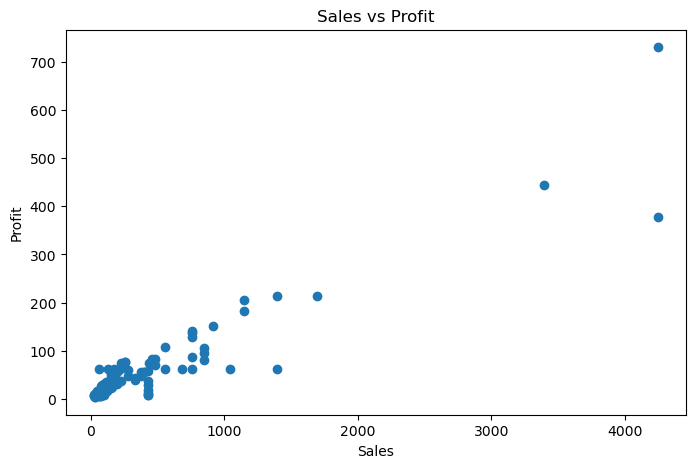

In [53]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Sales"], df["Profit"])
plt.title("Sales vs Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

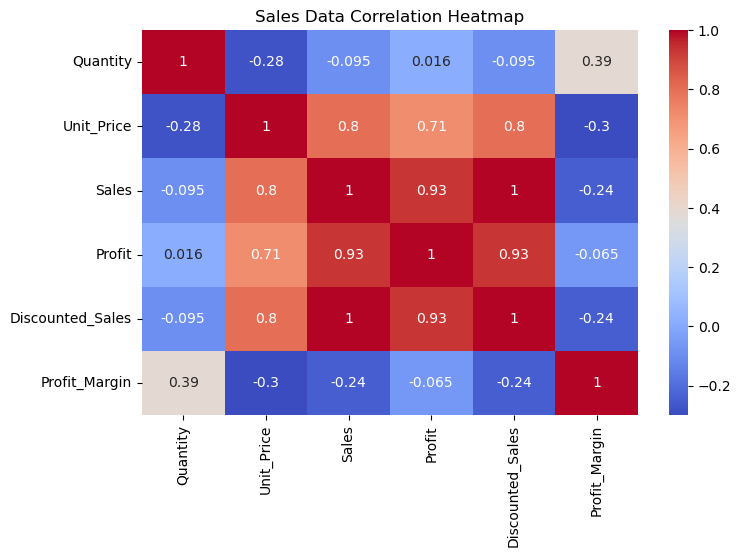

In [54]:
plt.figure(figsize=(8, 5))
sns.heatmap(df.select_dtypes(include=np.number).corr(),annot=True,cmap="coolwarm")
plt.title("Sales Data Correlation Heatmap")
plt.show()